#### Pulling the data

In [1]:
from baseband_analysis.core import BBData
from baseband_analysis.dev.Morphology_dev import singlebeam_to_input
import numpy as np
%matplotlib inline

Loading singelebeam file /arc/projects/chime_frb/BaseCat2/beamformed_files/FRB20181221A_23438043_beamformed.h5
Checking if baseband data was already de-smeared..
No DM in tiedbeam_baseband, so continuing on
---------Downsampling---------
Finding the best downsample. The SNr cutoff used is:  12


[2026-10-21 03:14:31,147] WARNING Pulse not in the valid range, noise will be added to search the full dump.
/opt/pysetup/baseband_analysis/core/signal.py:176: RuntimeWarning: Mean of empty slice
  return np.nanmean(power, axis=0) * np.sqrt(


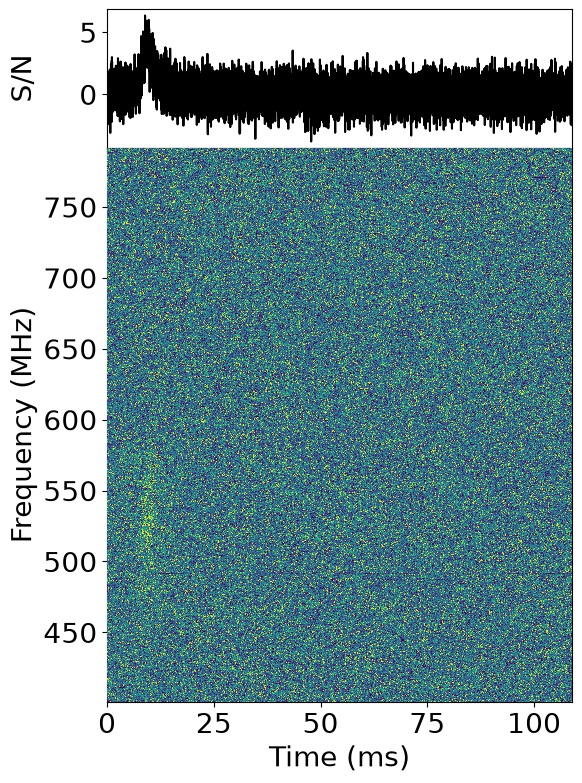

Profile already came in downsampled to:  4
SNR for initial downsampling factor 4: 6.352558392900571
The input dowsample was not bright enough. Finding the best downsample .....


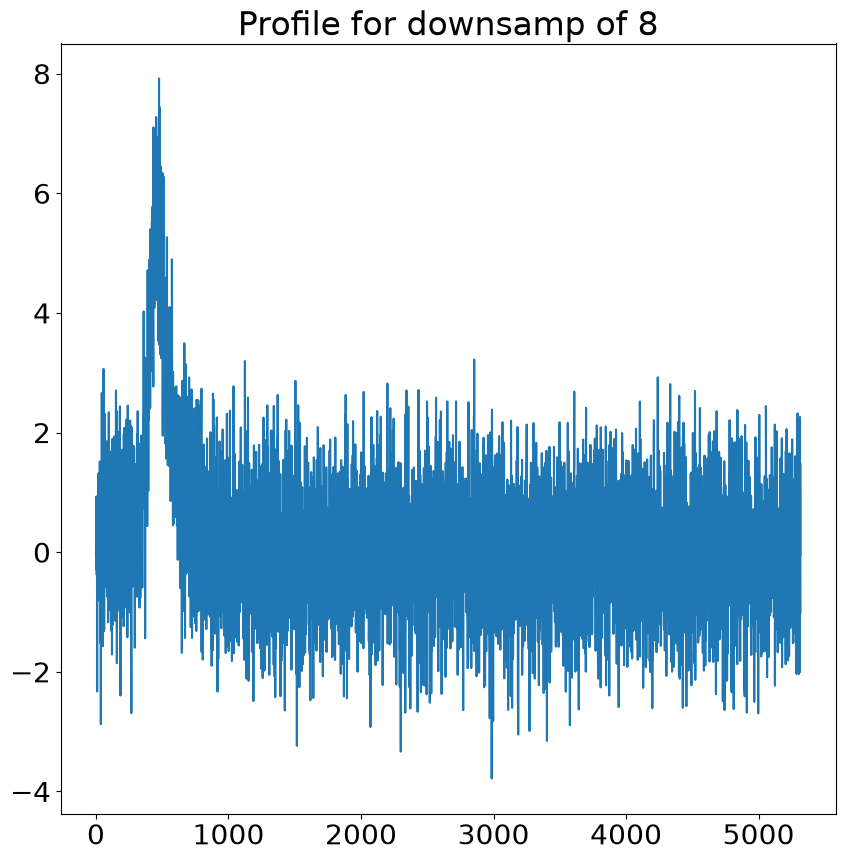

SNR for downsampling factor 8: 7.918472255058142


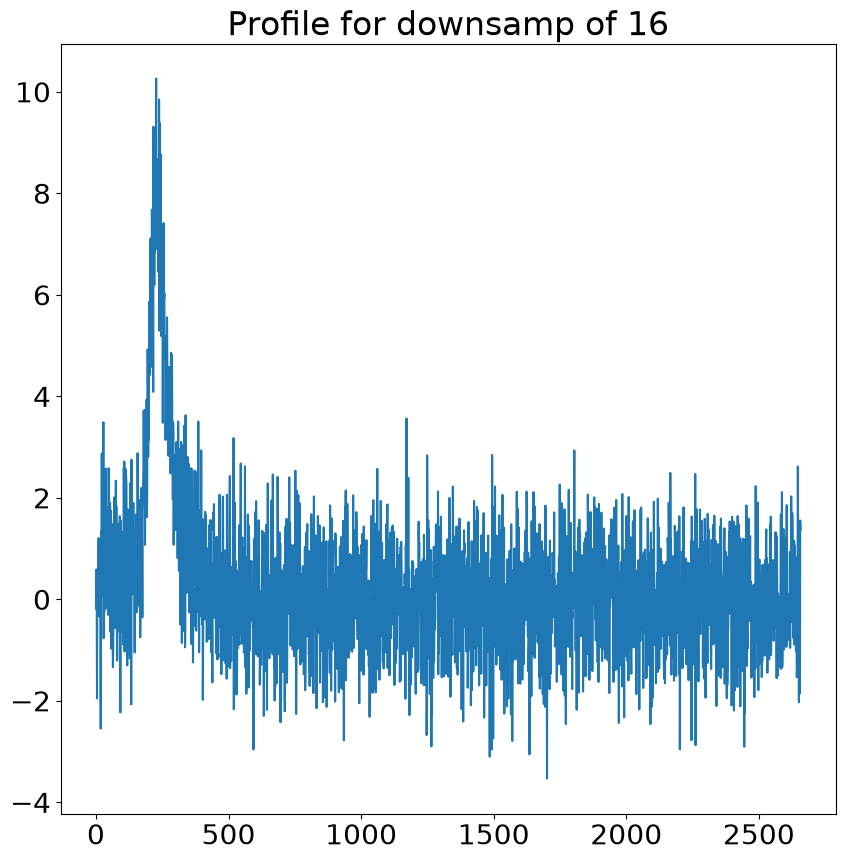

SNR for downsampling factor 16: 10.261608740906325


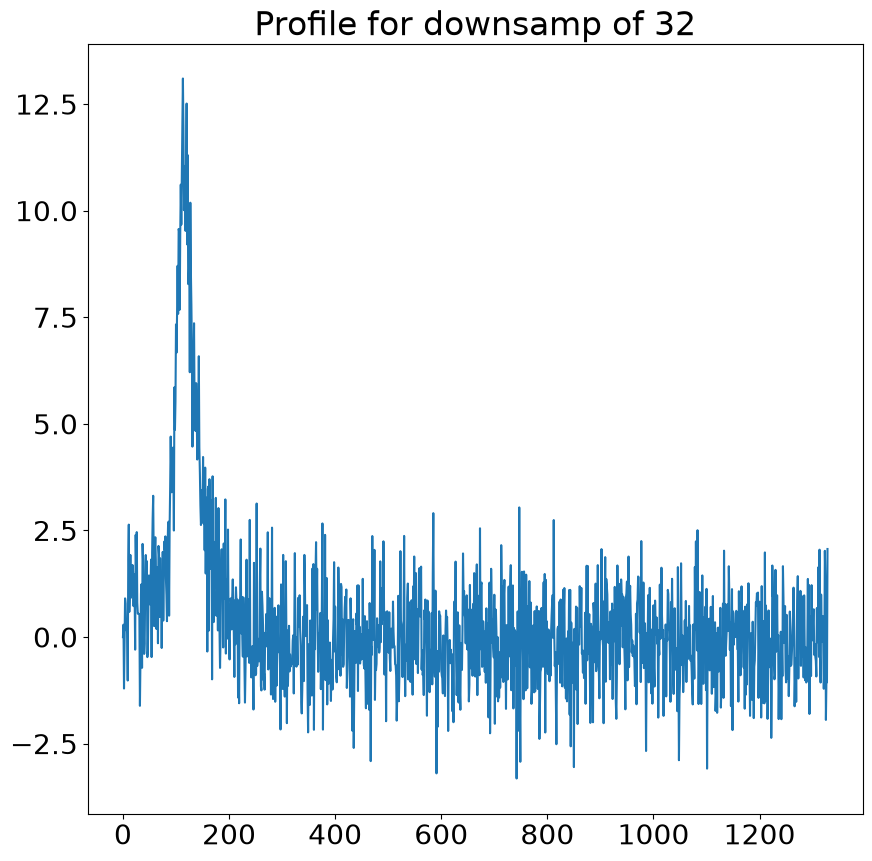

SNR for downsampling factor 32: 13.099028214724356
The final downsample is 32
We will use 32 as downsampling factor from now on
New downsampling factor != original factor. Going to re-run get_snr as a result to get a new power array


[2026-10-21 03:14:50,901] WARNING Pulse not in the valid range, noise will be added to search the full dump.


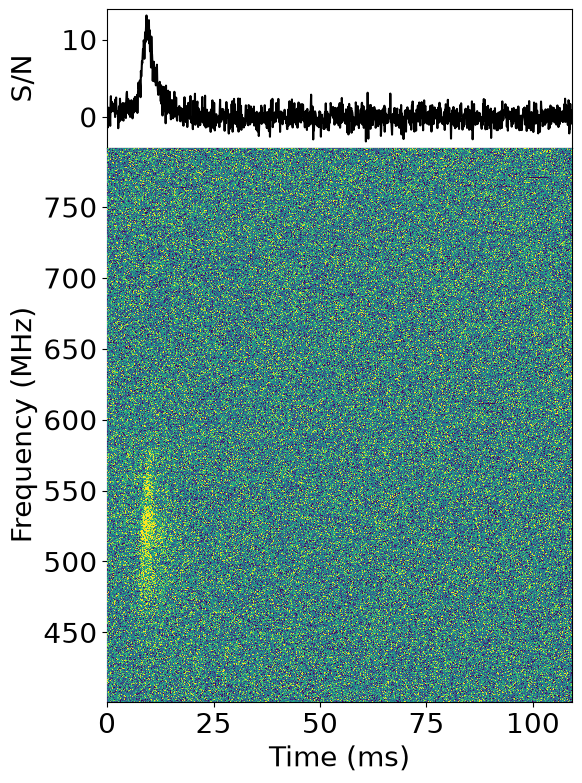

---------DM DETERMINATION---------
Running get_snr() to get an estimate on S/N maximizing DM


[2026-10-21 03:15:03,743] INFO Best DM found at 316.19601179767204 pc/cc
[2026-10-21 03:15:07,974] WARNING Pulse not in the valid range, noise will be added to search the full dump.
[2026-10-21 03:15:19,218] INFO Best DM found at 316.1960205972281 pc/cc


The S/N maximizing DM is 316.1960205972281 pc/cc
Grabbing the burst profile
Getting the signal
Running structure maximizing DM script
The structure maximizing DM is 316.32666120973676 pc/cc +/- 0.07237685363026441 pc/cc
Running get_snr() again now at the final DM of:  316.32666120973676


[2026-10-21 03:15:29,556] WARNING Pulse not in the valid range, noise will be added to search the full dump.


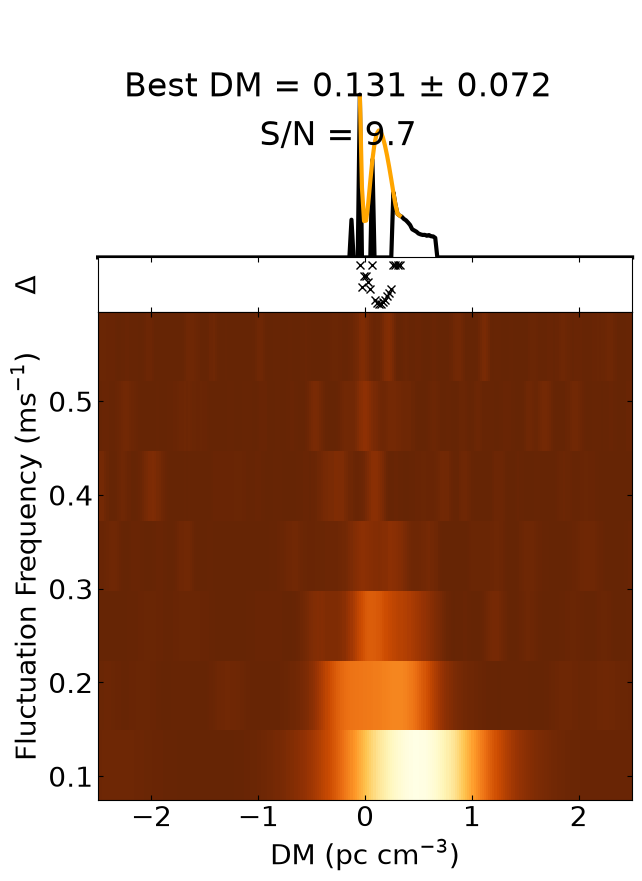

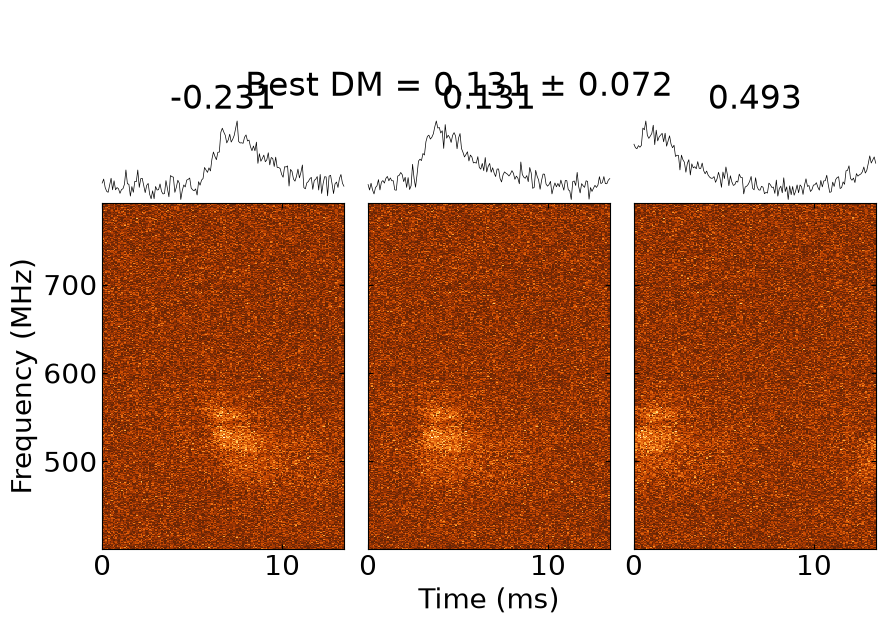

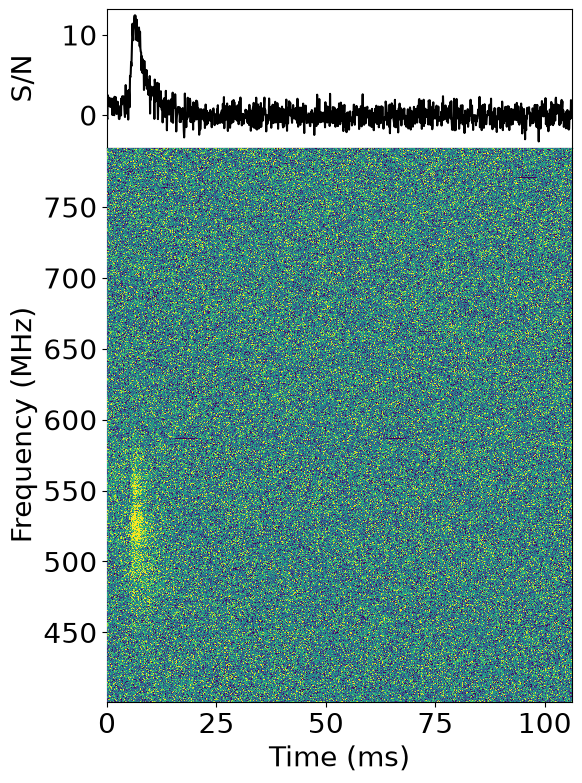

Getting the signal
Plotting a waterfall of the power


<Figure size 1000x1000 with 0 Axes>

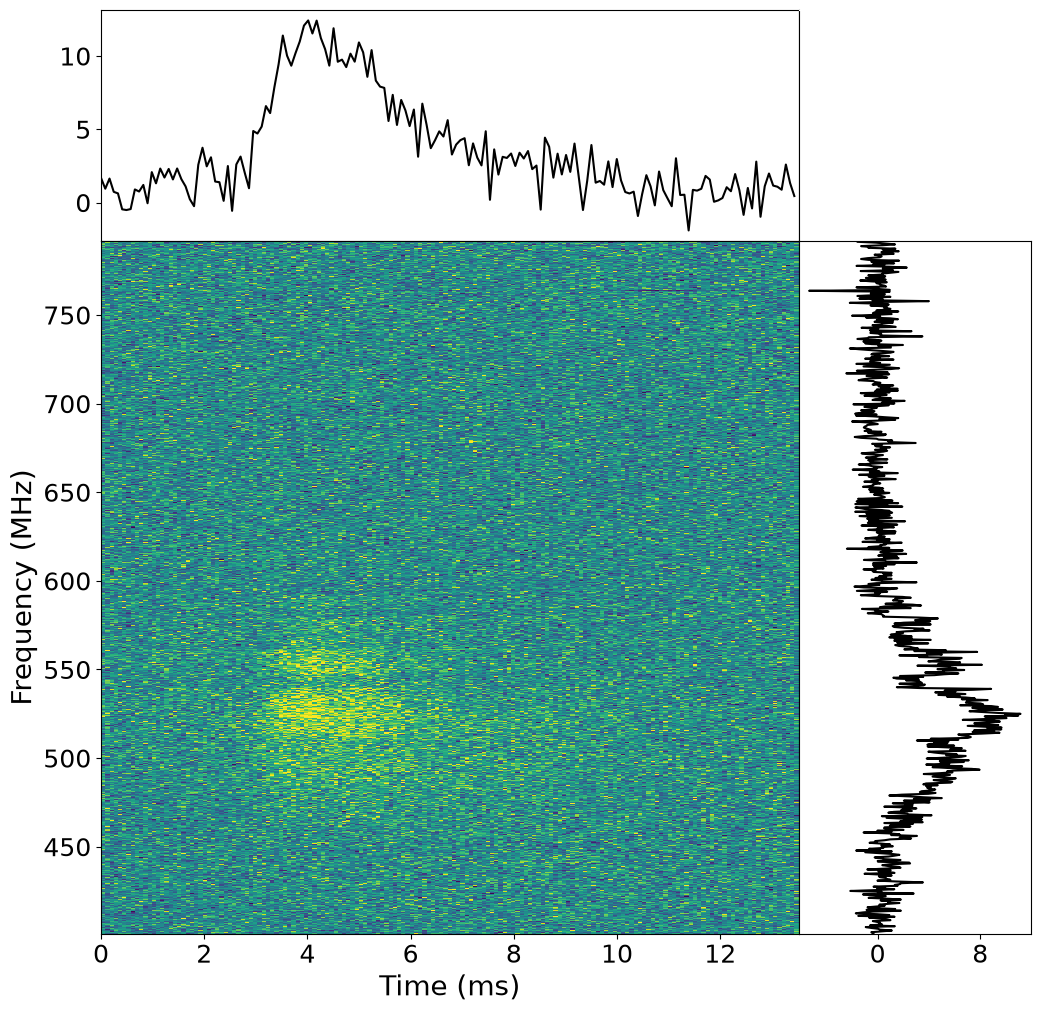

In [3]:
# event ID 22154974
# baseband file path:arc/projects/chime_frb/BaseCat2/beamformed_files/FRB20181209A_22154974_beamformed.h5

file = "/arc/projects/chime_frb/BaseCat2/beamformed_files/FRB20181221A_23438043_beamformed.h5"
print("Loading singelebeam file {}".format(file))
data = BBData.from_file(file)

data, freq_id, freq, power, valid_channels, DM, DM_err, downsampling_factor, profile, t_res, start, full_power = singlebeam_to_input(file,
                                                                                                                                     downsample = 4, # downsampling in time
                                                                                                                                     fit_DM = True, # getting a structure max DM 
                                                                                                                                     diagnostic_plots = True,
                                                                                                                                     snr_cutoff = 12,
                                                                                                                                     )



In [4]:
n_time = power.shape[1]
time = start + t_res * np.arange(n_time)

In [5]:
np.savez('event_23438043_BB.npz', power=power, freq=freq, time=time)
# or np.savez_compressed(...) if power is large and you want smaller files